<a href="https://colab.research.google.com/github/Argyrhspet1/MachineLearning_Project2/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importing Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

In [2]:
df=pd.read_csv("airline_passenger_satisfaction.csv")
df.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


#Plotting Values

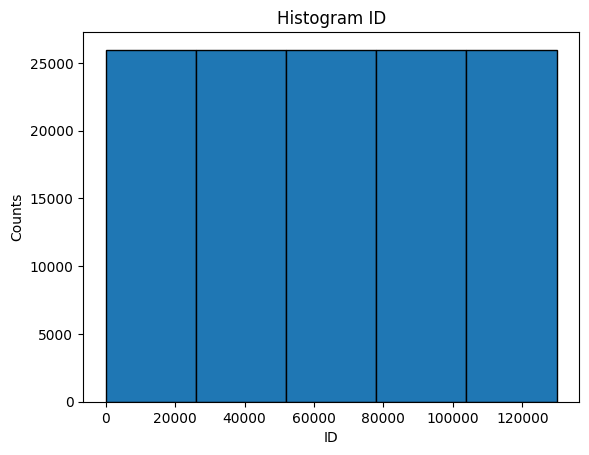

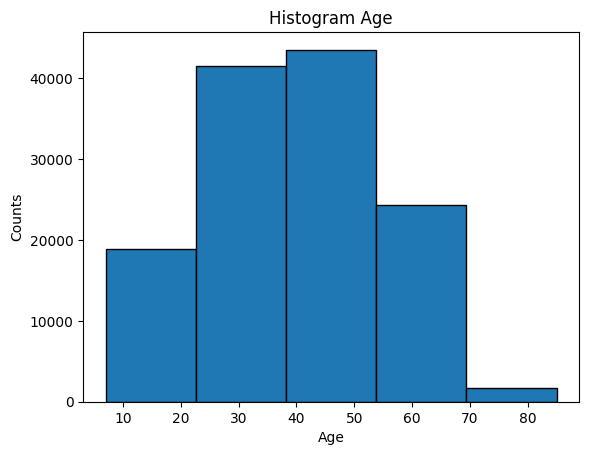

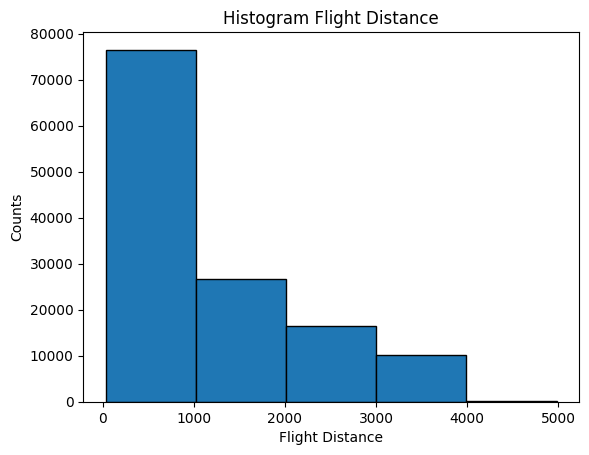

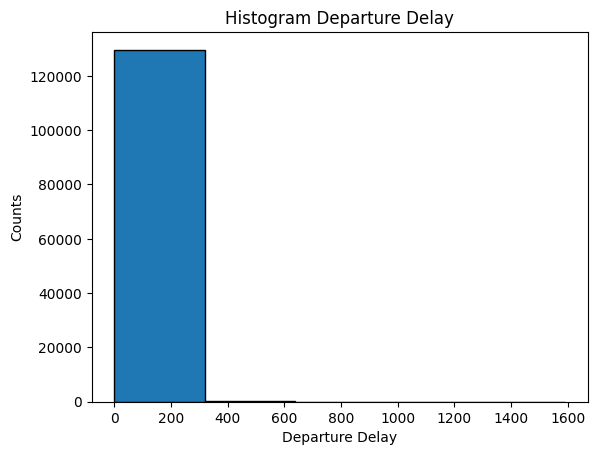

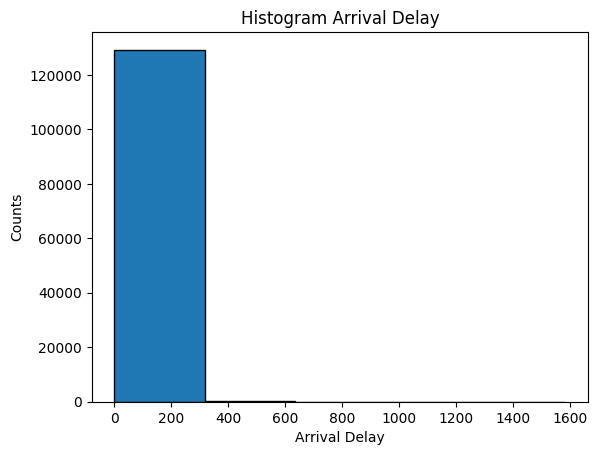

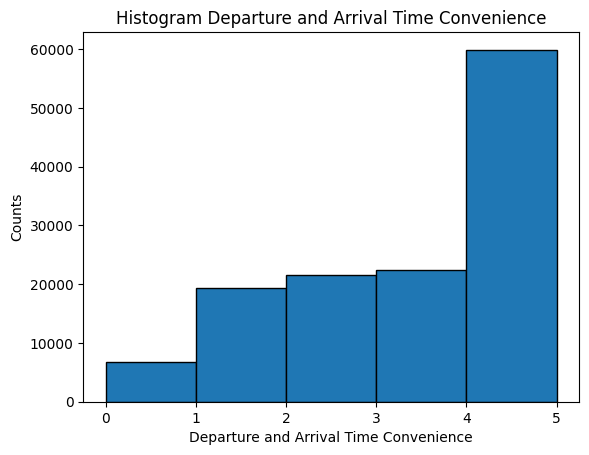

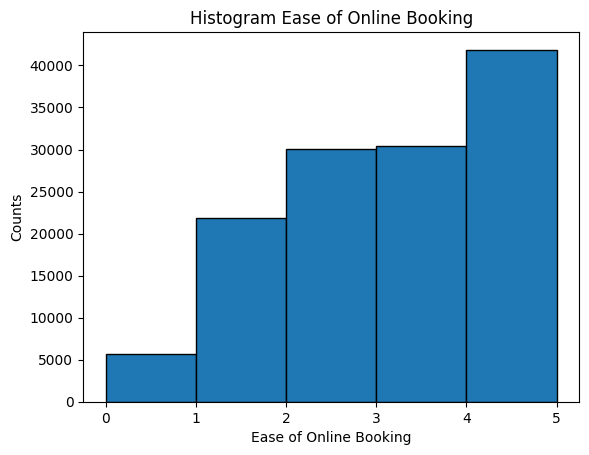

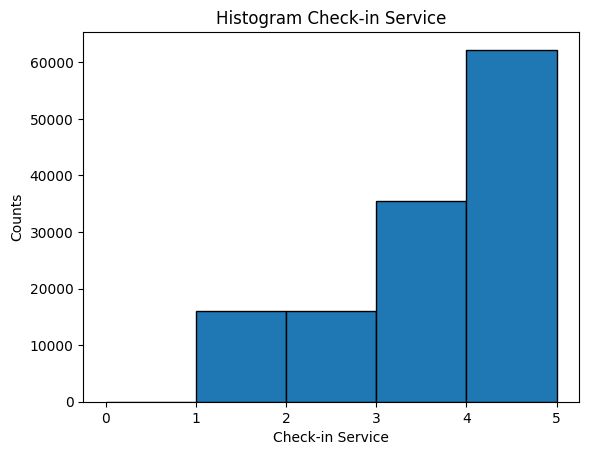

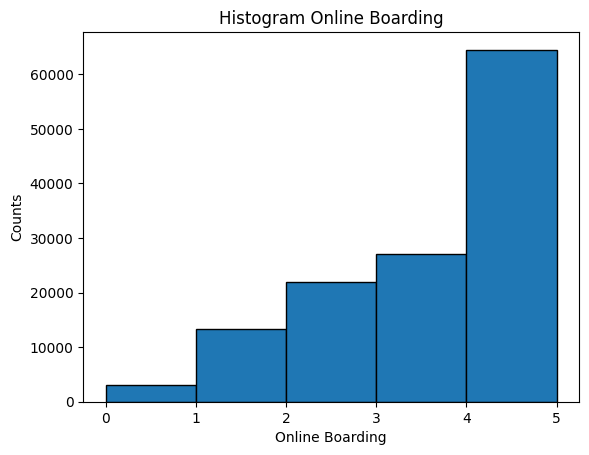

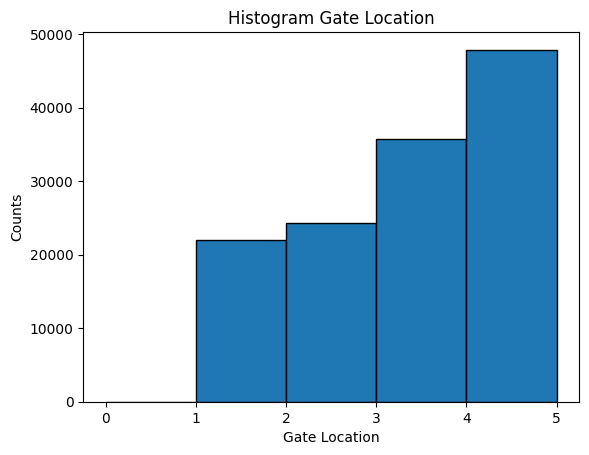

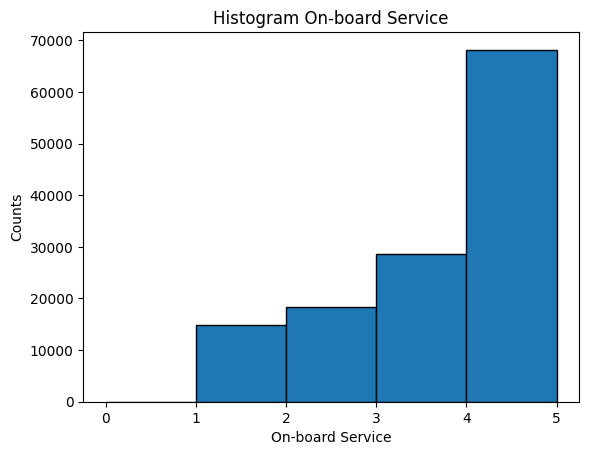

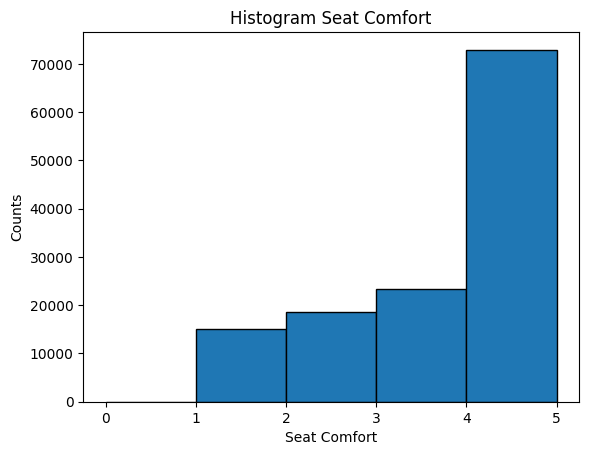

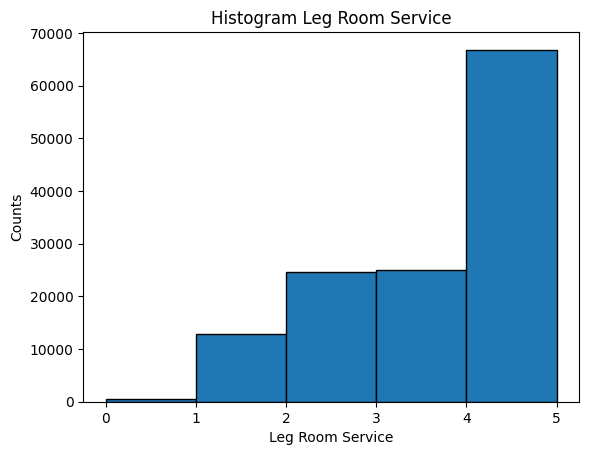

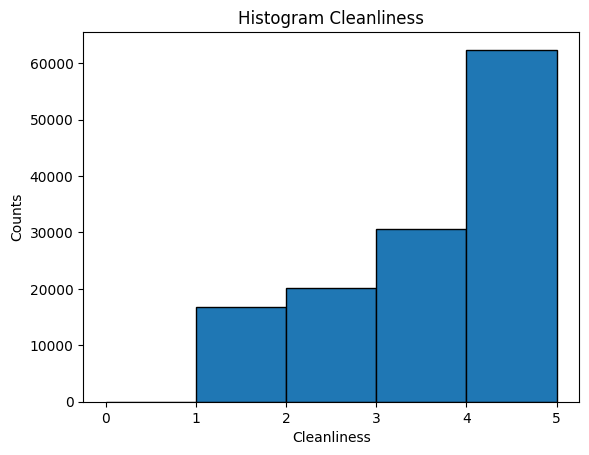

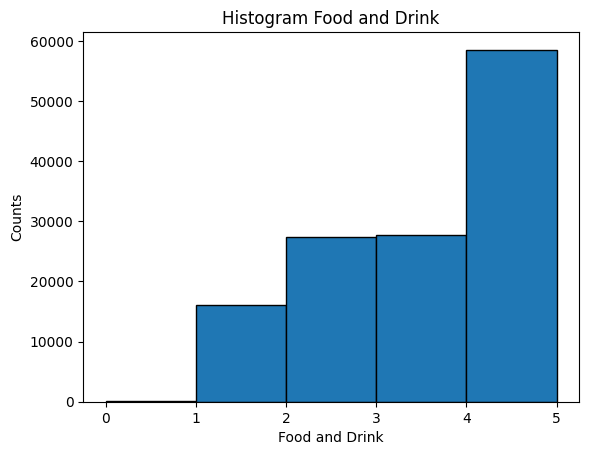

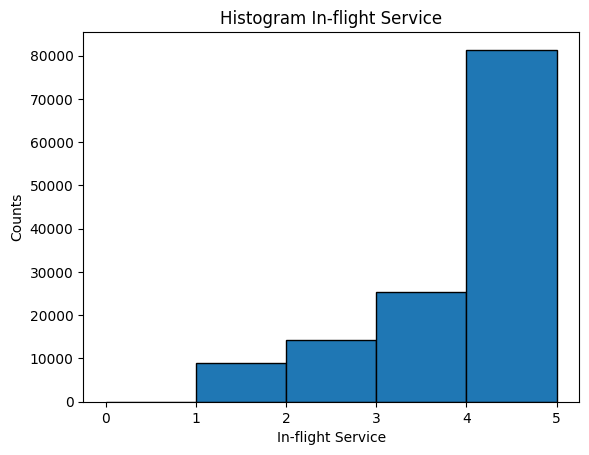

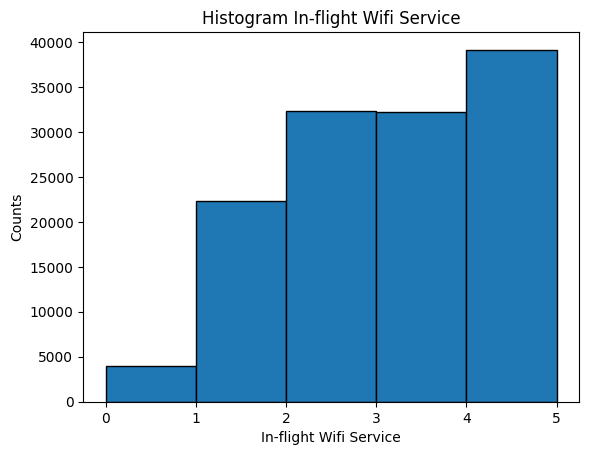

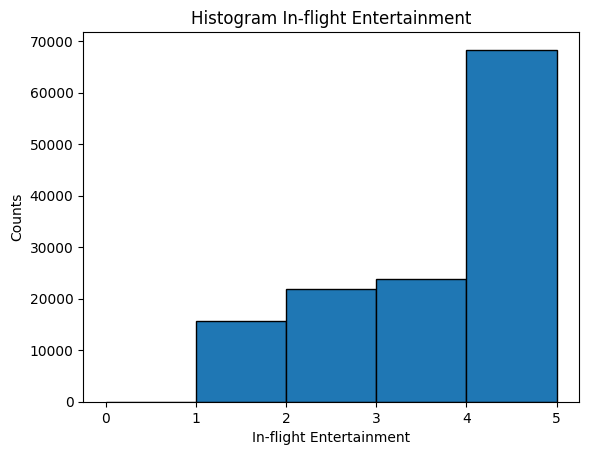

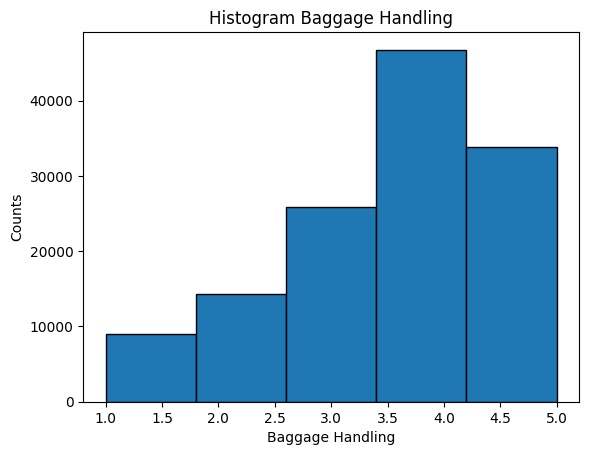

In [3]:
for x in df.columns:
  if df[x].dtype =='int' or df[x].dtype=='float':
    df[x].hist(bins=5, edgecolor='black')
    plt.title('Histogram '+x)
    plt.xlabel(x)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

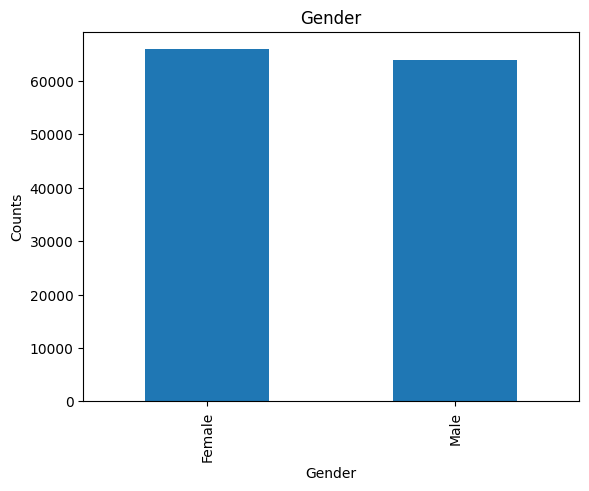

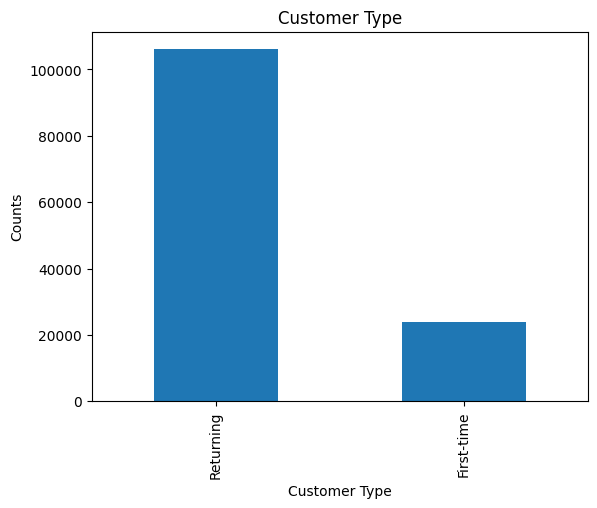

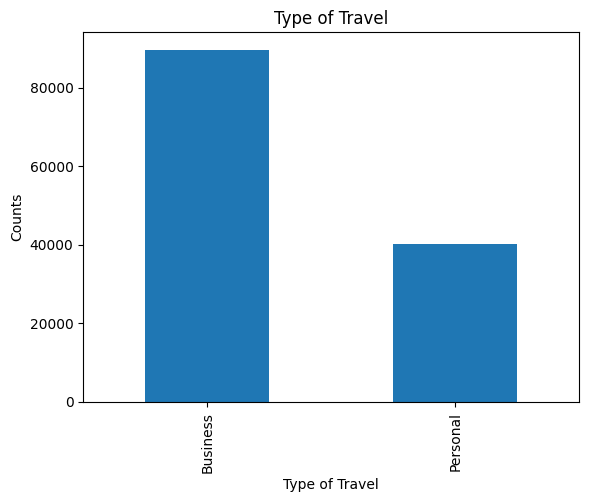

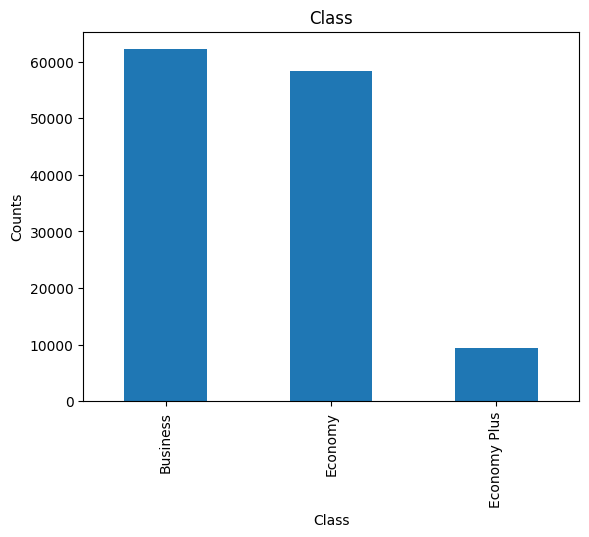

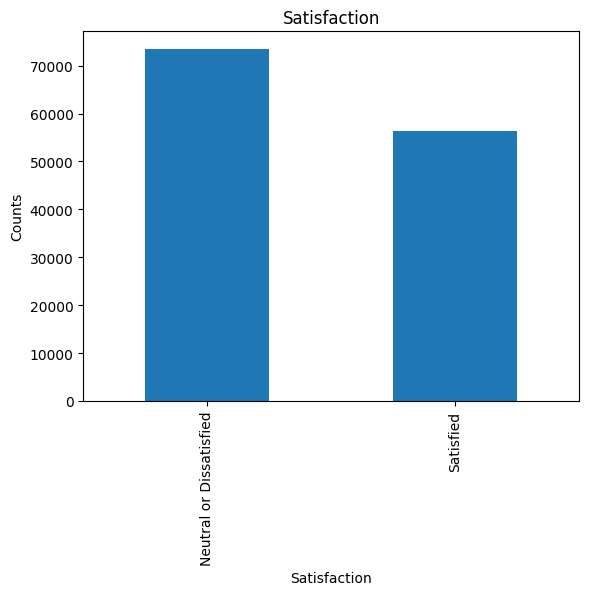

In [4]:
for x in df.columns:
  if df[x].dtype=='object':
    df[x].value_counts().plot(kind="bar")
    plt.title(x)
    plt.xlabel(x)
    plt.ylabel("Counts")
    plt.grid(False)
    plt.show()

The first value of the target variable Satisfaction which is Neutral/Dissatisfied counts approximately 73000 samples whereas the Satisfied value counts nearly 55000 samples. There is a slight difference in their numbers nevertheless this difference is not enough to describe the class as unbalanced.

#One Hot Encoding

In [5]:
df.dtypes

,0
ID,int64
Gender,object
Age,int64
Customer Type,object
Type of Travel,object
Class,object
Flight Distance,int64
Departure Delay,int64
Arrival Delay,float64
Departure and Arrival Time Convenience,int64


In [6]:
df["Gender"].value_counts()

,count
Gender,
Female,65899
Male,63981


In [7]:
df["Customer Type"].value_counts()

,count
Customer Type,
Returning,106100
First-time,23780


In [8]:
df["Class"].value_counts()

,count
Class,
Business,62160
Economy,58309
Economy Plus,9411


In [9]:
df["Type of Travel"].value_counts()

,count
Type of Travel,
Business,89693
Personal,40187


In [10]:
df = pd.get_dummies(
    df,
    columns=['Gender', 'Customer Type', 'Class', 'Type of Travel']
)

In [11]:
df= pd.get_dummies(
    df,
    columns=['Satisfaction'],
    drop_first=True
)

In [12]:
for x in df.columns:
  if df[x].dtype!='float':
    df[x]=df[x].astype(int)

#Train Test Split/ Data Normalization

In [13]:
df = df.dropna()

numerical_cols = [
    'Age',
    'Flight Distance',
    'Departure Delay',
    'Arrival Delay',
]
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

x = df.drop(columns=['Satisfaction_Satisfied']).to_numpy()
y = df['Satisfaction_Satisfied'].to_numpy()

seed = 0
test_size = 0.3
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=test_size,random_state=seed)

Scaling in KNN Classifier is very important because KNN is an algorithm that calculates distances using Euclidean/Manhattan distance and if we do not scale KNN it will take in to account only characteristics with the biggest values ignoring others that might be useful.

#Model Training

In [14]:
N= len(X_train)
k=[3,5,15,51, 151,int(N**(1/2))]
w=["uniform","distance"]

df2=pd.DataFrame()



In [17]:
results = []

for x in k:
  for y in w:
    knn = KNeighborsClassifier(n_neighbors=x, weights=y, metric='euclidean')
    knn.fit(X_train, y_train)

    y_train_pred = knn.predict(X_train)
    y_test_pred = knn.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    results.append({
        'k': x,
        'w': y,
        'train_acc': train_acc,
        'test_acc': test_acc,
    })


In [19]:
df2=pd.DataFrame(results)

In [21]:
df2['difference']=df2['train_acc']-df2['test_acc']

In [24]:
df2

,k,w,train_acc,test_acc,difference
0,3,uniform,0.874735,0.744305,0.130431
1,3,distance,1.000000,0.745592,0.254408
2,5,uniform,0.828839,0.727958,0.100881
3,5,distance,1.000000,0.732746,0.267254
4,15,uniform,0.731542,0.673257,0.058286
5,15,distance,1.000000,0.701882,0.298118
6,51,uniform,0.648025,0.622210,0.025815
7,51,distance,1.000000,0.680336,0.319664
8,151,uniform,0.599029,0.587227,0.011802
9,151,distance,1.000000,0.671377,0.328623


The best combination is k=3 and weight=distance because it achieved the highest accuracy score in the test test 0.745592.